In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/orders_clean.csv", parse_dates=["order_datetime"])
df["line_total"] = df["amount"] * df["quantity"]

In [2]:
print(df.shape)
print(df["line_total"].sum())
print(df["order_id"].nunique())
print(df["customer_id"].nunique())

(199997, 14)
316021416421.0
197628
151631


In [3]:
print(df.columns.tolist())
df.head(3)

['order_id', 'customer_id', 'item_id', 'order_datetime', 'amount', 'city', 'quantity', 'order_date', 'year', 'month', 'year_month', 'is_high_amount', 'is_high_quantity', 'line_total']


,order_id,customer_id,item_id,order_datetime,amount,city,quantity,order_date,year,month,year_month,is_high_amount,is_high_quantity,line_total
0,2714054,469662,21386,2015-10-15 08:50:56,597982.0,محمود آباد,1,2015-10-15,2015,10,2015-10,False,False,597982.0
1,11104039,3063877,248497,2018-02-11 00:29:26,980000.0,خرمدره,1,2018-02-11,2018,2,2018-02,False,False,980000.0
2,4228130,3184893,50144,2016-06-14 00:30:08,229358.0,قرچک,1,2016-06-14,2016,6,2016-06,False,False,229358.0


shamsi_year
1392      3.51
1393     19.27
1394     38.87
1395     68.36
1396    105.75
1397     80.26
Name: line_total, dtype: float64


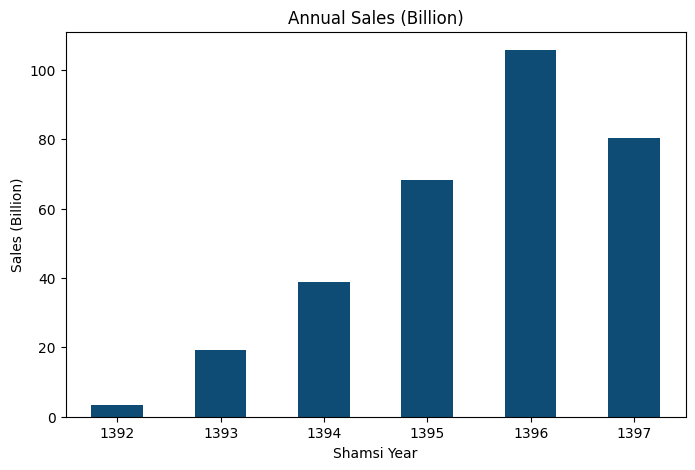

In [5]:
%matplotlib inline
from persiantools.jdatetime import JalaliDate

# ساخت ستون سال شمسی
dates = df["order_datetime"].dt.date
mapping = {d: JalaliDate.to_jalali(d.year, d.month, d.day).year for d in dates.unique()}
df["shamsi_year"] = dates.map(mapping)

# فروش هر سال به میلیارد
sales_by_year = (df.groupby("shamsi_year")["line_total"].sum() / 1e9).round(2)
print(sales_by_year)

# نمودار
fig, ax = plt.subplots(figsize=(8, 5))
sales_by_year.plot(kind="bar", ax=ax, color="#0F4C75")
ax.set_title("Annual Sales (Billion)")
ax.set_xlabel("Shamsi Year")
ax.set_ylabel("Sales (Billion)")
plt.xticks(rotation=0)
plt.show()

shamsi_year   1392  1393  1394   1395   1396   1397
shamsi_month                                       
1              NaN  0.75  2.22   3.77   6.47  10.49
2              NaN  0.99  2.72   3.99   5.64  11.90
3              NaN  0.92  2.92   4.56   6.20  12.16
4              NaN  1.13  2.23   5.43   6.93   8.91
5              NaN  1.25  2.76   5.46   7.79   8.62
6              NaN  1.28  3.06   5.28   8.97   7.99
7             0.35  1.59  3.10   4.87   7.87   6.99
8             0.29  1.27  3.24   5.41   8.38   7.42
9             0.49  1.89  3.39   5.45  12.13   5.78
10            0.51  2.05  3.85   6.94   9.28    NaN
11            0.78  2.47  4.51   7.21  11.44    NaN
12            1.09  3.68  4.88  10.00  14.66    NaN


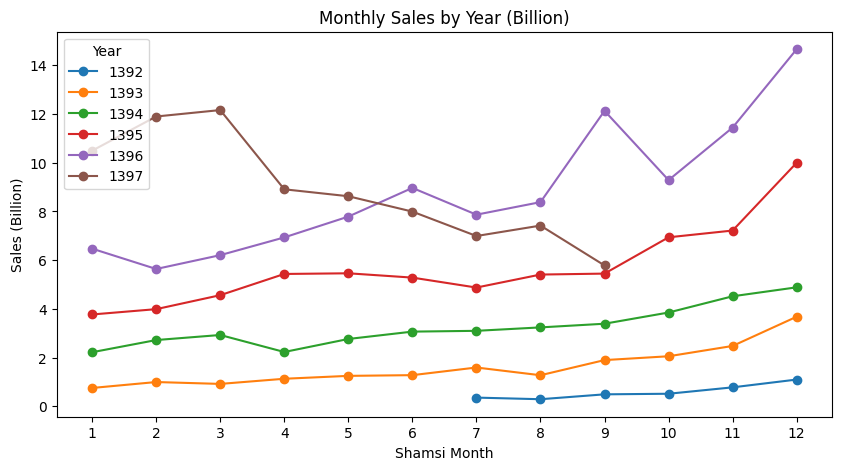

In [6]:
# ساخت ستون ماه شمسی
mapping_month = {d: JalaliDate.to_jalali(d.year, d.month, d.day).month for d in dates.unique()}
df["shamsi_month"] = dates.map(mapping_month)

# فروش هر ماه به تفکیک سال (میلیارد)
monthly = (df.groupby(["shamsi_year", "shamsi_month"])["line_total"].sum() / 1e9).unstack(0)
print(monthly.round(2))

# نمودار خطی
fig, ax = plt.subplots(figsize=(10, 5))
monthly.plot(ax=ax, marker="o")
ax.set_title("Monthly Sales by Year (Billion)")
ax.set_xlabel("Shamsi Month")
ax.set_ylabel("Sales (Billion)")
ax.set_xticks(range(1, 13))
ax.legend(title="Year")
plt.savefig("../reports/figures/eda_monthly_trend.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
%pip install arabic-reshaper python-bidi

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


city
تهران     165.50
اصفهان     10.38
مشهد        9.62
کرج         9.55
شیراز       6.65
رشت         5.78
اهواز       5.66
تبریز       4.14
یزد         3.85
قم          3.83
Name: line_total, dtype: float64
سهم تهران: 52.4 %
سهم ۱۰ شهر برتر: 71.2 %


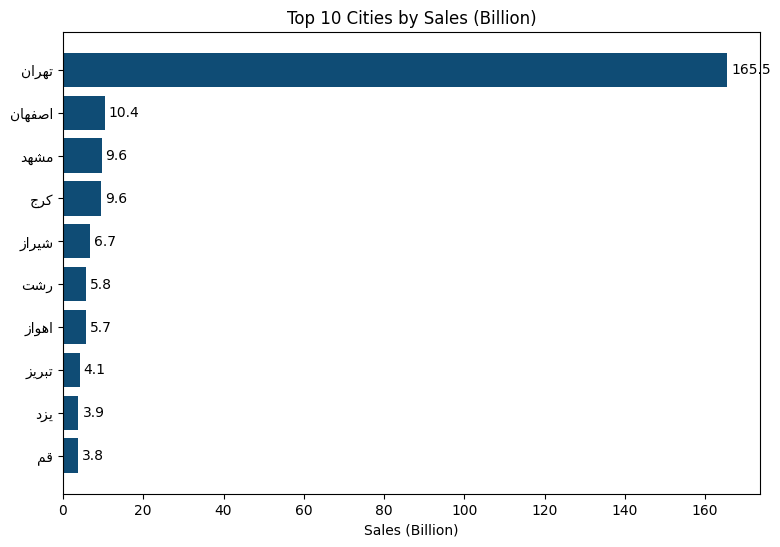

In [8]:
from arabic_reshaper import reshape
from bidi.algorithm import get_display

def fa(text):
    return get_display(reshape(str(text)))

total = df["line_total"].sum()
city_sales = df.groupby("city")["line_total"].sum().sort_values(ascending=False)
top10 = city_sales.head(10)

print((top10 / 1e9).round(2))
print("سهم تهران:", round(city_sales.iloc[0] / total * 100, 1), "%")
print("سهم ۱۰ شهر برتر:", round(top10.sum() / total * 100, 1), "%")

labels = [fa(c) for c in top10.index][::-1]
values = (top10.values / 1e9)[::-1]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(labels, values, color="#0F4C75")
ax.set_title("Top 10 Cities by Sales (Billion)")
ax.set_xlabel("Sales (Billion)")
for i, v in enumerate(values):
    ax.text(v + 1, i, f"{v:.1f}", va="center")
plt.savefig("../reports/figures/eda_top10_cities.png", dpi=150, bbox_inches="tight")
plt.show()

مشتریان یکتا: 151631
مشتریان تکراری: 27536
درصد تکراری: 18.2 %
میانگین سفارش هر مشتری: 1.3
order_id
1 order       81.8
2-3 orders    15.5
4-5 orders     1.9
5+ orders      0.7
Name: count, dtype: float64


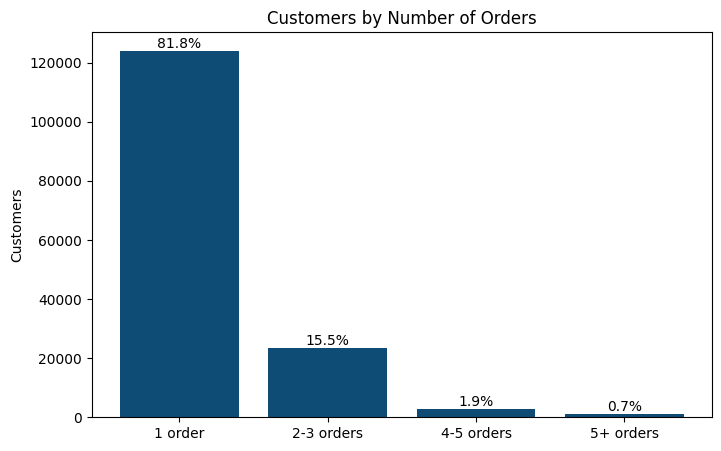

customer_id
957912     150
1153061     91
509634      45
1145709     35
4782393     32
Name: order_id, dtype: int64


In [9]:
# تعداد سفارش یکتای هر مشتری
orders_per_customer = df.groupby("customer_id")["order_id"].nunique()

total_customers = len(orders_per_customer)
repeat_customers = (orders_per_customer > 1).sum()

print("مشتریان یکتا:", total_customers)
print("مشتریان تکراری:", repeat_customers)
print("درصد تکراری:", round(repeat_customers / total_customers * 100, 1), "%")
print("میانگین سفارش هر مشتری:", round(orders_per_customer.mean(), 2))

# گروه‌بندی مثل Power BI
groups = pd.cut(
    orders_per_customer,
    bins=[0, 1, 3, 5, float("inf")],
    labels=["1 order", "2-3 orders", "4-5 orders", "5+ orders"],
)
dist = groups.value_counts().reindex(["1 order", "2-3 orders", "4-5 orders", "5+ orders"])
pct = (dist / total_customers * 100).round(1)
print(pct)

# نمودار
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(dist.index, dist.values, color="#0F4C75")
ax.set_title("Customers by Number of Orders")
ax.set_ylabel("Customers")
for i, (v, p) in enumerate(zip(dist.values, pct.values)):
    ax.text(i, v, f"{p}%", ha="center", va="bottom")
plt.savefig("../reports/figures/eda_customer_orders.png", dpi=150, bbox_inches="tight")
plt.show()

# ۵ مشتری با بیشترین سفارش (برای قدم بعدی)
print(orders_per_customer.sort_values(ascending=False).head(5))

In [10]:
# --- بخش ۱: دو مشتری غیرعادی ---
odd_ids = [957912, 1153061]
total = df["line_total"].sum()

for cid in odd_ids:
    c = df[df["customer_id"] == cid]
    print("مشتری:", cid)
    print("  سفارش یکتا:", c["order_id"].nunique())
    print("  ردیف:", len(c))
    print("  فروش (میلیون):", round(c["line_total"].sum() / 1e6))
    print("  سهم از کل فروش:", round(c["line_total"].sum() / total * 100, 2), "%")
    print("  شهرهای متفاوت:", c["city"].nunique())
    print("  کالاهای متفاوت:", c["item_id"].nunique())
    print("  اولین سفارش:", c["order_datetime"].min().date())
    print("  آخرین سفارش:", c["order_datetime"].max().date())
    print()

# --- بخش ۲: مبلغ‌ها و تعدادهای بزرگ ---
print("آمار مبلغ هر عدد:")
print(df["amount"].describe(percentiles=[0.5, 0.99, 0.999]).round(0))
print()
print("آمار تعداد:")
print(df["quantity"].describe(percentiles=[0.5, 0.99, 0.999]))
print()
print("۵ ردیف با بیشترین مبلغ کل:")
df.nlargest(5, "line_total")[["order_id", "customer_id", "city", "amount", "quantity", "line_total"]]

مشتری: 957912
  سفارش یکتا: 150
  ردیف: 150
  فروش (میلیون): 427
  سهم از کل فروش: 0.14 %
  شهرهای متفاوت: 33
  کالاهای متفاوت: 149
  اولین سفارش: 2014-04-14
  آخرین سفارش: 2018-11-27

مشتری: 1153061
  سفارش یکتا: 91
  ردیف: 91
  فروش (میلیون): 171
  سهم از کل فروش: 0.05 %
  شهرهای متفاوت: 2
  کالاهای متفاوت: 90
  اولین سفارش: 2014-10-18
  آخرین سفارش: 2018-12-06

آمار مبلغ هر عدد:
count    1.999970e+05
mean     1.458226e+06
std      5.451010e+06
min      1.000000e+00
50%      3.211010e+05
99%      2.105538e+07
99.9%    4.953211e+07
max      1.530000e+09
Name: amount, dtype: float64

آمار تعداد:
count    199997.000000
mean          1.261224
std           1.801199
min           1.000000
50%           1.000000
99%           5.000000
99.9%        20.000000
max         500.000000
Name: quantity, dtype: float64

۵ ردیف با بیشترین مبلغ کل:


,order_id,customer_id,city,amount,quantity,line_total
32036,8556100,643657,تهران,1.530000e+09,1,1.530000e+09
189643,1122141,716378,تهران,1.188245e+07,30,3.564736e+08
123281,9925599,5437450,تهران,1.999083e+07,14,2.798716e+08
102923,6616927,3656845,تهران,2.648716e+07,8,2.118972e+08
71671,5908757,838763,تهران,3.579673e+07,5,1.789837e+08
